# Import Libraries

In [ ]:
import numpy as np
import pandas as pd


# Import Data

In [ ]:
# Import data.
loan_data_inputs_train = pd.read_csv('loan_data_inputs_train.csv')
loan_data_inputs_test = pd.read_csv('loan_data_inputs_test.csv')
feature_df = pd.read_csv('feature.csv')

# Explore Data

In [ ]:
inputs = pd.concat([loan_data_inputs_train, loan_data_inputs_test], axis=0)

In [ ]:
inputs = inputs[inputs['loan_status'].isin(['Charged Off','Does not meet the credit policy. Status:Charged Off'])]
# Here we take only the accounts that were charged-off (written-off).

In [ ]:
pd.options.display.max_rows = None
# Sets the pandas dataframe options to display all columns/ rows.

In [ ]:
inputs.shape

In [ ]:
inputs.isnull().sum()

# Dependent Variables

In [ ]:
inputs['recovery_rate'] = inputs['recoveries'] / inputs['funded_amnt']
# We calculate the dependent variable for the LGD model: recovery rate.
# It is the ratio of recoveries and funded amount.

In [ ]:
inputs['recovery_rate'].describe()
# Shows some descriptive statisics for the values of a column.

In [ ]:
inputs['recovery_rate'] = np.where(inputs['recovery_rate'] > 1, 1, inputs['recovery_rate'])
inputs['recovery_rate'] = np.where(inputs['recovery_rate'] < 0, 0, inputs['recovery_rate'])
# We set recovery rates that are greater than 1 to 1 and recovery rates that are less than 0 to 0.

In [ ]:
inputs['recovery_rate'].describe()
# Shows some descriptive statisics for the values of a column.

# Explore Dependent Variables

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [ ]:
plt.hist(inputs['recovery_rate'], bins = 100)
# We plot a histogram of a variable with 100 bins.

In [ ]:
plt.hist(inputs['recovery_rate'], bins = 50)
# We plot a histogram of a variable with 50 bins.

In [ ]:
inputs['recovery_rate_0_1'] = np.where(inputs['recovery_rate'] == 0, 0, 1)
# We create a new variable which is 0 if recovery rate is 0 and 1 otherwise.

In [ ]:
plt.hist(inputs['recovery_rate_0_1'], bins = 50)
# We plot a histogram of a variable with 50 bins.

### Beta regression for LGD

In [ ]:
feature_name = feature_df.to_numpy()
feature_name = feature_name.flatten().tolist()
feature_name

In [ ]:
# Here, from the dataframe with inputs for testing, we keep the same variables that we used in our final PD model.
inputs = inputs.loc[: , feature_name + ['recovery_rate']]
inputs.head()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.othermod.betareg import BetaModel

# Beta regression typically works  when the target variable is bounded between 0 and 1,
# so we will use 'recovery_rate' in this context, assuming it's bounded between 0 and 1.

# Stage 1: Prepare the data
lgd_inputs, lgd_targets = inputs.drop('recovery_rate', axis = 1), inputs['recovery_rate']
lgd_inputs_train, lgd_inputs_test, lgd_targets_train, lgd_targets_test = train_test_split(lgd_inputs, lgd_targets.clip(1e-6, 1-1e-6), test_size=0.2, random_state=42)

lgd_inputs_train.info()

In [ ]:
# Add of an intercept to the input data
lgd_inputs_train = sm.add_constant(lgd_inputs_train)
lgd_inputs_test = sm.add_constant(lgd_inputs_test)

# Stage 2: Create the Beta regression model
beta_model = BetaModel(lgd_targets_train, lgd_inputs_train)

# Ajust the model and get the model summary to check the results
beta_model_fit = beta_model.fit()
print(beta_model_fit.summary())

In [ ]:
# Predicting on the test set
lgd_predictions_proba = beta_model_fit.predict(lgd_inputs_test)
lgd_predictions_proba = lgd_predictions_proba.to_numpy()
lgd_predictions_proba

In [ ]:
import pickle
pickle.dump(beta_model_fit, open('lgd_model.sav', 'wb'))
# Here we export our model to a 'SAV' file with file name 'lgd_model.sav'.

# Convert numpy array to DataFrame
feature_df = pd.DataFrame(feature_name)

# Export to CSV
feature_df.to_csv('feature_lgd.csv', index=False)

In [ ]:
lgd_targets_test_temp = lgd_targets_test
lgd_targets_test_temp.reset_index(drop = True, inplace = True)
# We reset the index of a dataframe.

df_actual_predicted_probs = pd.concat([lgd_targets_test_temp, pd.DataFrame(lgd_predictions_proba)], axis = 1)
# Concatenates two dataframes.

df_actual_predicted_probs.columns = ['lgd_targets_test_temp', 'lgd_predictions_proba']

df_actual_predicted_probs.index = lgd_inputs_test.index
df_actual_predicted_probs.head()

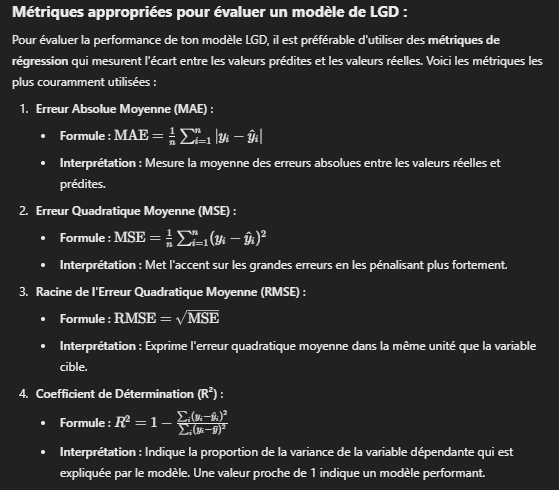



In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_true = df_actual_predicted_probs['lgd_targets_test_temp'].values
y_pred = df_actual_predicted_probs['lgd_predictions_proba'].values

# MAE
mae = mean_absolute_error(y_true, y_pred)
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# MSE
mse = mean_squared_error(y_true, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")

# RMSE
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# R?
r2 = r2_score(y_true, y_pred)
print(f"Coefficient of Determination (R?): {r2:.4f}")

Interpr?tation des r?sultats?:
MAE : Plus la MAE est faible, plus les pr?dictions sont proches des valeurs r?elles en moyenne.
RMSE : Comme la RMSE p?nalise davantage les grandes erreurs, une valeur faible indique que le mod?le n'a pas de grandes erreurs de pr?diction.
R? : Une valeur proche de 1 signifie que le mod?le explique bien la variance des donn?es. Une valeur n?gative ou proche de 0 indique que le mod?le n'explique pas bien les donn?es.

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_true, y_pred, alpha=0.5)
plt.plot([0, 1], [0, 1], 'r--')  # Ligne y = x for ref
plt.xlabel('Actual LGD')
plt.ylabel('Predicted LGD')
plt.title('Actual vs. Predicted LGD')
plt.show()

## Interpretation of each metric :
1. Mean Absolute Error (MAE): 0.0496
Interpretation: MAE measures the mean absolute error between predictions and actual values.  
A MAE of 0.0496 means that, on average, your model's predictions deviate from the actual values by 4.96%.
Evaluation: Given that the LGD varies between 0 and 1 (0% to 100%), an average error of less than 5% is relatively low, which is positive.

2. Mean Squared Error (MSE): 0.0057
Interpretation: MSE is the mean squared error between predictions and actual values.  
It penalizes larger errors.
Assessment: An MSE of 0.0057 is quite low, indicating that large errors are rare in your model.

3. Root Mean Squared Error (RMSE): 0.0755
Interpretation: RMSE is the square root of MSE.  
It is expressed in the same units as the LGD.  
An RMSE of 0.0755 means that the standard deviation of residuals is 7.55%.
Assessment: An RMSE of less than 10% is generally considered acceptable in financial models, but this depends on the context and industry standards.

4. Coefficient of Determination (R?) : 0.3553
Interpretation: The R? indicates the proportion of LGD variance that is explained by your model.  
An R? of 0.3553 means that your model explains around 35.53% of total LGD variability.
Assessment: An R? of 35% is relatively low, suggesting that the model doesn't capture much of the variance in the data.

## Overall analysis:

#### Low errors but low R?:
Although the mean errors are low (MAE and RMSE), the low R? indicates that the model fails to explain much of the LGD variance in the test data.

#### Possible explanation: 
This may indicate that the model is accurate on average (predicts values close to the true mean), but does not capture well the specific variations in LGD for different observations.

## Detailed interpretation:

#### LGD distribution:
Low variance: If the LGD is highly concentrated around a mean value (for example, most observations have an LGD close to 0.05), the model may obtain low mean errors by simply predicting this mean, which would explain the low R?.
Verification: I recommend plotting the histogram of the actual LGD to check its distribution.
Limited predictive ability:
Missing variables: The low R? suggests that some important explanatory variables for LGD are not included in the model.
Complexity of the phenomenon: LGD is influenced by many factors, including macroeconomic variables, specific loan characteristics, and legal aspects of collection.

## Recommendations for improving the model :

#### Add relevant explanatory variables:
Collateral quality: If possible, include information on collateral associated with loans.
Type of financial product: Different types of loans may have different LGDs.
Collection history : Variables indicating the efficiency of the collection process may be useful.

#### Analyze model residuals :
Residuals plot: Plots residuals (error between actual and predicted values) against predicted values to detect patterns.
Heteroskedasticity: Checks whether the variance of residuals is constant.  
Heteroscedasticity may indicate that the model is not well specified.

#### Use more complex models :
Non-linear models: Consider using models such as decision trees, random forests or gradient boosting (e.g. XGBoost), which can capture non-linear relationships.
Neural networks: These can be useful if you have a large volume of data and complex relationships.

#### Cross-validation:
Model robustness: Use cross-validation to evaluate model performance on different subsets of the data.
Avoid overlearning: Make sure the model generalizes well and isn't overlearned on training data.

#### Segment data:
Clustering:Group loans into homogeneous segments (e.g. by industry, loan amount, etc.) and train specific models for each segment.
Benefit: This can improve accuracy by capturing segment-specific patterns.

#### Feature Engineering:
Create new variables: Combine or transform existing variables to extract more information.
Interaction between variables: Consider including interaction terms if this makes sense.
